In [1]:
#0 Prerequisites

import sys
import os
import numpy as np
import matplotlib.pyplot as plt
sys.path.append("/data/bsm/software/installed/madgraph/3.7.3/")
import madgraph.various.lhe_parser as lhe_parser

lhe_path = "/data/amorosanu/MadGraph_outputs/gg_tt/Events/run_02_decayed_1/unweighted_events.lhe"
m_t = 173.6
m_tt = []
cos = []
cosbar = []
beta = []
theta = []
weight = []

def boost(p, q):
    E, px, py, pz = q
    M = np.sqrt(E**2 - px**2 - py**2 - pz**2) 
    bx, by, bz = px/E, py/E, pz/E
    b2 = bx**2 + by**2 + bz**2
    if b2 == 0:
        return np.copy(p)
    gamma = E / M
    gamma2 = (gamma - 1.0) / b2
    bp = bx * p[1] + by * p[2] + bz * p[3]

    p_prime = np.zeros(4)
    p_prime[0] = gamma * (p[0] - bp)
    p_prime[1] = p[1] + gamma2 * bp * bx - gamma * p[0] * bx
    p_prime[2] = p[2] + gamma2 * bp * by - gamma * p[0] * by
    p_prime[3] = p[3] + gamma2 * bp * bz - gamma * p[0] * bz

    return p_prime

def square_root_matrix(M):
    eigenval, eigenvec = eigh(M)
    eigenval = np.sqrt(np.maximum(0.0, eigenval))
    sqrt_rho = eigenvec @ np.diag(eigenval) @ eigenvec.conj().T
    return sqrt_rho


In [2]:
for event in lhe_parser.EventFile(lhe_path):

    #1. Kinematic reconstruction of ttbar pair

    elec = [p for p in event if p.pid == 11]
    posi = [p for p in event if p.pid == -11]
    ve = [p for p in event if p.pid == 12]
    vebar = [p for p in event if p.pid == -12]
    b = [p for p in event if p.pid == 5]
    bbar = [p for p in event if p.pid == -5]

    if not elec or not posi or not b or not bbar or not ve or not vebar:
        continue

    p_elec = np.array([elec[0].E, elec[0].px, elec[0].py, elec[0].pz])
    p_posi = np.array([posi[0].E, posi[0].px, posi[0].py, posi[0].pz])
    p_ve = np.array([ve[0].E, ve[0].px, ve[0].py, ve[0].pz])
    p_vebar = np.array([vebar[0].E, vebar[0].px, vebar[0].py, vebar[0].pz])
    p_b = np.array([b[0].E, b[0].px, b[0].py, b[0].pz])
    p_bbar = np.array([bbar[0].E, bbar[0].px, bbar[0].py, bbar[0].pz])

    p_t = p_b + p_posi + p_ve 
    p_tbar = p_bbar + p_elec + p_vebar
    p_tt = p_t + p_tbar
    m_tt.append(np.sqrt(p_tt[0]**2 - p_tt[1]**2 - p_tt[2]**2 - p_tt[3]**2))
    beta.append(np.sqrt(max(0.0, 1 - 4 * m_t ** 2 / m_tt[-1] ** 2)))
    
    #2. Boost in ZMF frame and Helicity frame comp.

    p_t_zmf = boost(p_t, p_tt)
    p_t_vec = p_t_zmf[1:4]
    p_top_mod = np.linalg.norm(p_t_vec)

    z_hat = np.array([0.0, 0.0, 1.0])
    
    if p_top_mod > 0:
        k_hat = p_t_vec / p_top_mod
        cos_theta = np.dot(z_hat, k_hat)
        if cos_theta < 0:
            z_hat = - z_hat
            cos_theta = - cos_theta
        sin_theta = np.sqrt(1 - cos_theta ** 2)
        theta.append(2 * np.arccos(cos_theta) / np.pi)
        r_hat = (z_hat - k_hat * cos_theta) / sin_theta
        n_hat = np.cross(z_hat, k_hat) / sin_theta
    else:
        k_hat = [0.0, 0.0, 1.0]
        r_hat = [1.0, 0.0, 0.0]
        n_hat = [0.0, 1.0, 0.0]

    #3. Obtain angles of antilepton in top rest frame

    p_posi_t = boost(p_posi, p_tt)
    p_posi_t = boost(p_posi, p_t)
    p_posi_vec = p_posi_t[1:4]
    p_posi_mod = np.linalg.norm(p_posi_vec)
    if p_posi_mod > 0:
        p_posi_dir = p_posi_vec / np.linalg.norm(p_posi_vec)
        cos.append((np.dot(p_posi_dir, k_hat), np.dot(p_posi_dir, r_hat), np.dot(p_posi_dir, n_hat)))
    else:
        cos.append((0, 0, 0))

    #4. Obtain angles of the lepton in anti-top rest frame

    p_elec_t = boost(p_elec, p_tt)
    p_elec_t = boost(p_elec, p_tbar)
    p_elec_vec = p_elec_t[1:4]
    p_elec_mod = np.linalg.norm(p_elec_vec)
    if p_elec_mod > 0:
        p_elec_dir = p_elec_vec / np.linalg.norm(p_elec_vec)
        cosbar.append((np.dot(p_elec_dir, k_hat), np.dot(p_elec_dir, r_hat), np.dot(p_elec_dir, n_hat)))
    else:
        cosbar.append((0, 0, 0))




346.0082402571189


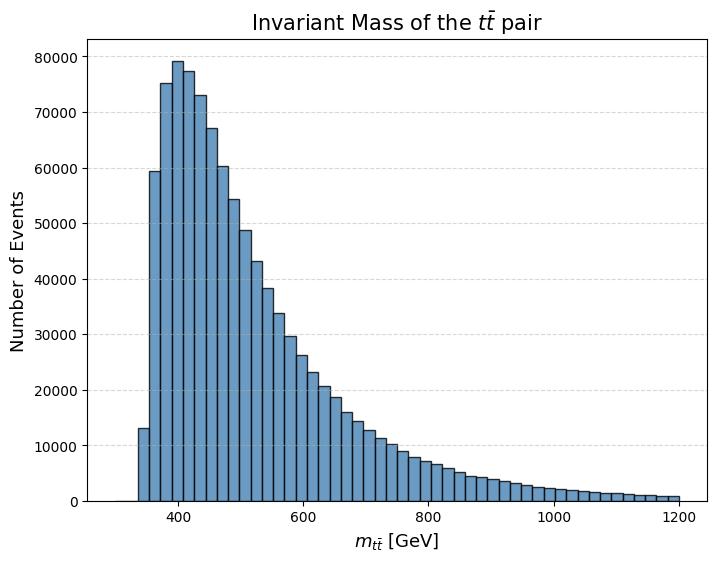

In [ ]:
#5.1 ttbar pair invariant mass distribution

plt.figure(figsize=(8, 6))
n, bins, patches = plt.hist(
    m_tt,
    bins=50, 
    range=(300, 1200), 
    color='steelblue', 
    edgecolor='black', 
    alpha=0.8
)

plt.title('Invariant Mass of the $t\\bar{t}$ pair', fontsize=15)
plt.xlabel('$m_{t\\bar{t}}$ [GeV]', fontsize=13)
plt.ylabel('Number of Events', fontsize=13)
plt.grid(axis='y', alpha=0.5, linestyle='--')
plt.show()

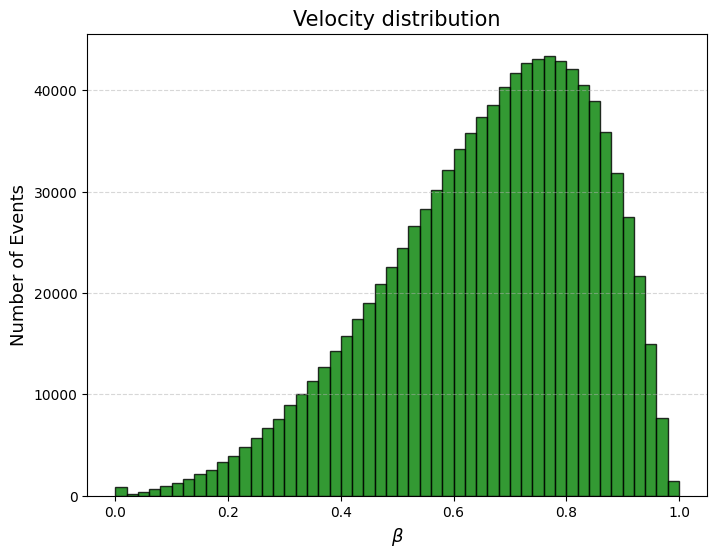

In [4]:
#5.2 beta distribution

plt.figure(figsize=(8, 6))
n, bins, patches = plt.hist(
    beta,
    bins=50, 
    range=(0, 1), 
    color='green', 
    edgecolor='black', 
    alpha=0.8
)

plt.title('Velocity distribution', fontsize=15)
plt.xlabel('$\\beta$', fontsize=13)
plt.ylabel('Number of Events', fontsize=13)
plt.grid(axis='y', alpha=0.5, linestyle='--')
plt.show()

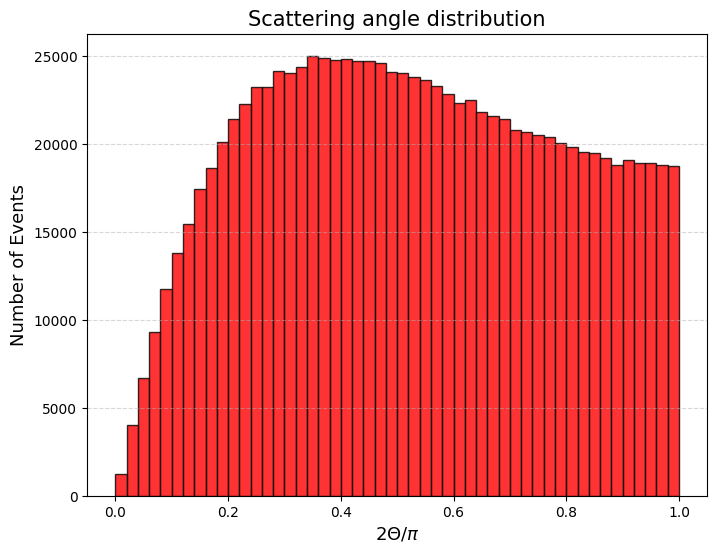

In [5]:
#5.3 theta distribution

plt.figure(figsize=(8, 6))
n, bins, patches = plt.hist(
    theta,
    bins=50, 
    range=(0, 1), 
    color='red', 
    edgecolor='black', 
    alpha=0.8
)

plt.title('Scattering angle distribution', fontsize=15)
plt.xlabel('$2\\Theta/\\pi$', fontsize=13)
plt.ylabel('Number of Events', fontsize=13)
plt.grid(axis='y', alpha=0.5, linestyle='--')
plt.show()

In [51]:
#6 Binning angular distributions
import pandas as pd

bin_n = 45
df = pd.DataFrame({'m_tt': m_tt, 'theta': theta, 'cos': cos, 'cosbar': cosbar})
df = df[df['m_tt'] < 1000]
df['payload'] = list(zip(df.cos, df.cosbar))
df['m_tt_bins'] = pd.cut(df['m_tt'], bins = bin_n)
df['theta_bins'] = pd.cut(df['theta'], bins = bin_n)

binned_matrix = (
    df.groupby(['m_tt_bins', 'theta_bins'], observed=False)['payload']
    .apply(list)
    .unstack(level='theta_bins')
)


In [52]:
#7 Reconstruction of density matrix

I = np.array([[1, 0], [0, 1]], dtype=complex)
sigma_x = np.array([[0, 1], [1, 0]], dtype=complex)
sigma_y = np.array([[0, -1j], [1j, 0]], dtype=complex)
sigma_z = np.array([[1, 0], [0, -1]], dtype=complex)
sigma = [sigma_x, sigma_y, sigma_z]

def reco_rho(bin_data):

    weight = len(bin_data)
    B = np.zeros(3)
    Bbar = np.zeros(3)
    C = np.zeros((3,3))
    for cos, cosbar in bin_data:
        for i in range(3):
            B[i] += 3 * cos[i] / weight
            Bbar[i] -= 3 * cosbar[i] / weight
            for j in range(3):
                C[i,j] -= 9 * cos[i] * cosbar[j] / weight

    rho = np.kron(I, I)
    for i in range(3):
        rho += B[i] * (np.kron(sigma[i], I))
        rho += Bbar[i] * (np.kron(I, sigma[i]))
        for j in range(3):
            rho += C[i,j] * (np.kron(sigma[i],sigma[j]))

    if not np.allclose(rho, rho.conj().T, atol=1e-10):
        rho = 0.5 * ( rho + rho.conj().T ) # Hermiticity

    eigenvalues, eigenvectors = np.linalg.eigh(rho)
    eigenvalues_clipped = np.clip(eigenvalues, a_min=0, a_max=None)
    rho = eigenvectors @ np.diag(eigenvalues_clipped) @ eigenvectors.conj().T # positive semi-definitness

    trace = np.trace(rho)
    if trace > 0:
        rho = rho / trace #unit trace
    else:
        rho = np.kron(I, I) * 1/4

    return rho

def distrib_num(bin_data):
    return len(bin_data)

In [53]:
#8 Quantum information calculation
from scipy.linalg import eigh

def concurrence_calc(rho):
    
    sqrt_rho = square_root_matrix(rho)
    rho_star = np.conj(rho)
    sigma_double_y = np.kron(sigma_y, sigma_y)
    rho_tilde = sqrt_rho @ sigma_double_y @ rho_star @ sigma_double_y @ sqrt_rho

    eigenval = eigh(rho_tilde, eigvals_only = True)
    eigenval = np.sqrt(np.maximum(0.0, eigenval))
    eigenval = np.sort(eigenval)[::-1]
    concurrence = max(0.0, eigenval[0] - eigenval[1] - eigenval[2] - eigenval[3])
    return concurrence


/tmp/ipykernel_3718886/3325024178.py:32: RuntimeWarning: divide by zero encountered in divide
  M_c2 = 2.0 * m_t / np.sqrt(1.0 - beta2_c2)


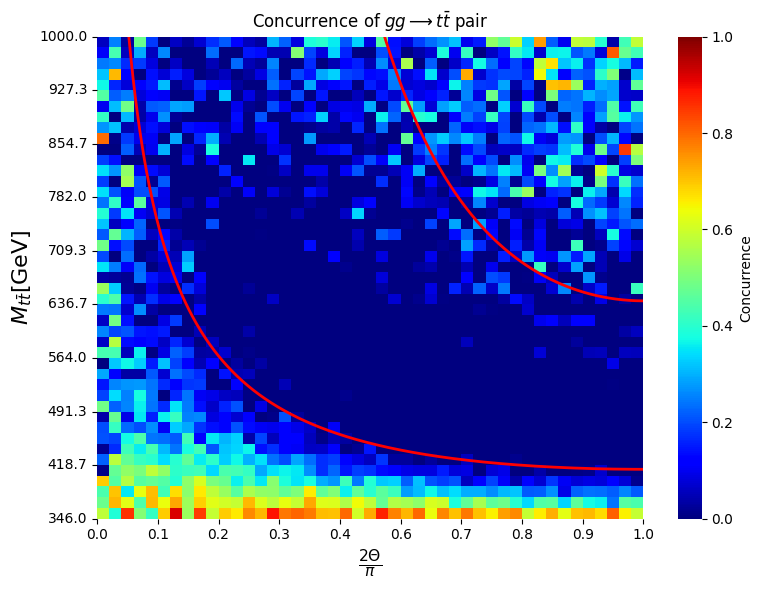

In [54]:
#9.1 Concurrence in terms of m_tt
import seaborn as sns

def process_cell(cell):
    if isinstance(cell, list) and len(cell) > 0:
        return concurrence_calc(reco_rho(cell))
    else:
        return np.nan

processed_map = binned_matrix.map(process_cell)

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    processed_map, 
    cmap='jet',      
    vmin=0.0,         
    vmax=1.0, 
    cbar_kws={'label': 'Concurrence'},
    ax=ax
)

bin_n_y, bin_n_x = processed_map.shape
m_min, m_max = 346, 1000.0
theta_fine = np.linspace(1e-4, np.pi/2, 500)
sin_t = np.sin(theta_fine)
sin2_t = sin_t**2
sin4_t = sin_t**4
beta2_c1 = (1.0 + sin2_t - np.sqrt(2.0) * sin_t) / (1.0 + sin4_t)
beta2_c2 = 1.0 / np.sqrt(1.0 + sin4_t) 
M_c1 = 2.0 * m_t / np.sqrt(1.0 - beta2_c1)
M_c2 = 2.0 * m_t / np.sqrt(1.0 - beta2_c2)
X_pixels = (theta_fine / (np.pi / 2.0)) * bin_n_x
Y1_pixels = ((M_c1 - m_min) / (m_max - m_min)) * bin_n_y
Y2_pixels = ((M_c2 - m_min) / (m_max - m_min)) * bin_n_y
ax.plot(X_pixels, Y1_pixels, color='red', linewidth=2.0)
ax.plot(X_pixels, Y2_pixels, color='red', linewidth=2.0)

ax.invert_yaxis()
num_ticks = 10
x_positions = np.linspace(0, bin_n_x, num_ticks)
y_positions = np.linspace(0, bin_n_y, num_ticks)
x_values = np.linspace(0, 1, num_ticks)
y_values = np.linspace(m_min, m_max, num_ticks)
x_labels = [f"{val:.1f}" for val in x_values]
y_labels = [f"{val:.1f}" for val in y_values]

ax.set_xticks(x_positions)
ax.set_xticklabels(x_labels, rotation=0) 
ax.set_yticks(y_positions)
ax.set_yticklabels(y_labels, rotation=0)

ax.set_title(r"Concurrence of $gg \longrightarrow t\bar{t}$ pair ")
ax.set_xlabel(r"$\frac{2\Theta}{\pi}$", fontsize=16)
ax.set_ylabel(r"$M_{t\bar{t}}[\mathrm{GeV}]$", fontsize=16)

plt.tight_layout()
plt.show()

/tmp/ipykernel_3718886/915571880.py:31: RuntimeWarning: divide by zero encountered in divide
  M_c2 = 2.0 * m_t / np.sqrt(1.0 - beta2_c2)


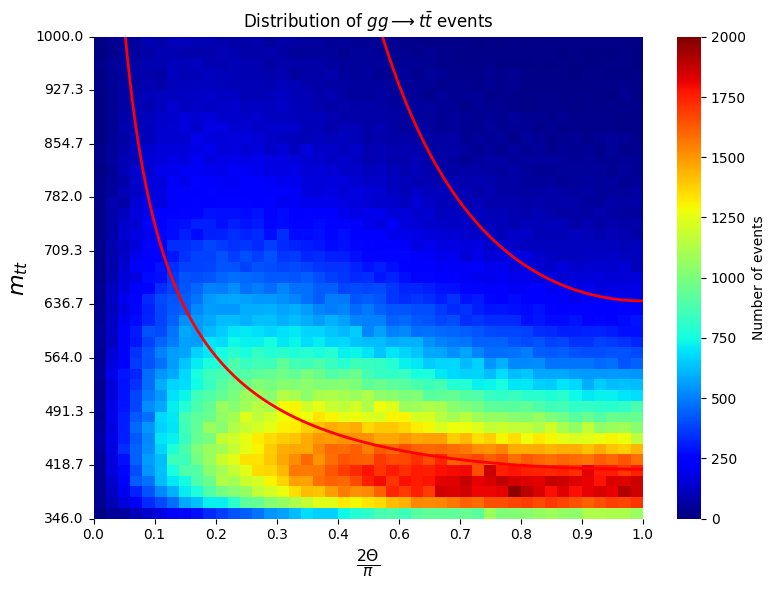

In [62]:
#9.2 Distribution in terms of m_tt

def process_cell(cell):
    if isinstance(cell, list) and len(cell) > 0:
        return distrib_num(cell)
    else:
        return np.nan

processed_map = binned_matrix.map(process_cell)

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    processed_map, 
    cmap='jet',      
    vmin=0.0,         
    vmax=2000, 
    cbar_kws={'label': 'Number of events'},
    ax=ax
)

bin_n_y, bin_n_x = processed_map.shape
m_min, m_max = 346, 1000.0
theta_fine = np.linspace(1e-4, np.pi/2, 500)
sin_t = np.sin(theta_fine)
sin2_t = sin_t**2
sin4_t = sin_t**4
beta2_c1 = (1.0 + sin2_t - np.sqrt(2.0) * sin_t) / (1.0 + sin4_t)
beta2_c2 = 1.0 / np.sqrt(1.0 + sin4_t) 
M_c1 = 2.0 * m_t / np.sqrt(1.0 - beta2_c1)
M_c2 = 2.0 * m_t / np.sqrt(1.0 - beta2_c2)
X_pixels = (theta_fine / (np.pi / 2.0)) * bin_n_x
Y1_pixels = ((M_c1 - m_min) / (m_max - m_min)) * bin_n_y
Y2_pixels = ((M_c2 - m_min) / (m_max - m_min)) * bin_n_y
ax.plot(X_pixels, Y1_pixels, color='red', linewidth=2.0)
ax.plot(X_pixels, Y2_pixels, color='red', linewidth=2.0)

ax.invert_yaxis()
num_ticks = 10
x_positions = np.linspace(0, bin_n_x, num_ticks)
y_positions = np.linspace(0, bin_n_y, num_ticks)
x_values = np.linspace(0, 1, num_ticks)
y_values = np.linspace(m_min, m_max, num_ticks)
x_labels = [f"{val:.1f}" for val in x_values]
y_labels = [f"{val:.1f}" for val in y_values]

ax.set_xticks(x_positions)
ax.set_xticklabels(x_labels, rotation=0) 
ax.set_yticks(y_positions)
ax.set_yticklabels(y_labels, rotation=0)

ax.set_title(r"Distribution of $gg \longrightarrow t\bar{t}$ events")
ax.set_xlabel(r"$\frac{2\Theta}{\pi}$", fontsize=16)
ax.set_ylabel(r"$m_{tt}$", fontsize=16)

plt.tight_layout()
plt.show()

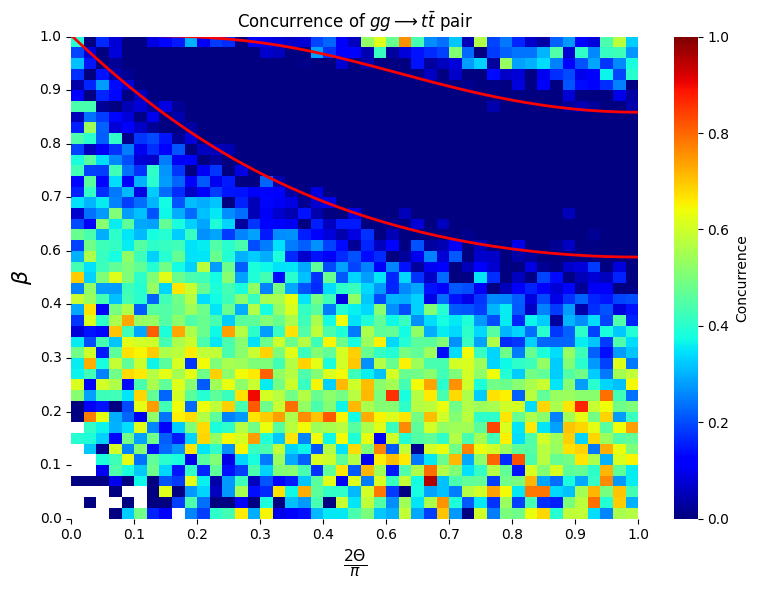

In [56]:
#10.1 Concurrence in terms of beta

bin_n = 45
df2 = pd.DataFrame({'beta': beta, 'theta': theta, 'cos': cos, 'cosbar': cosbar})
df2['payload'] = list(zip(df2.cos, df2.cosbar))
df2['beta_bins'] = pd.cut(df2['beta'], bins = bin_n)
df2['theta_bins'] = pd.cut(df2['theta'], bins = bin_n)

binned_matrix2 = (
    df2.groupby(['beta_bins', 'theta_bins'], observed=False)['payload']
    .apply(list)
    .unstack(level='theta_bins')
)

def process_cell(cell):
    if isinstance(cell, list) and len(cell) > 0:
        return concurrence_calc(reco_rho(cell))
    else:
        return np.nan
    
processed_map = binned_matrix2.map(process_cell)

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    processed_map, 
    cmap='jet',      
    vmin=0.0,         
    vmax=1.0, 
    cbar_kws={'label': 'Concurrence'},
    ax=ax
)

bin_n_y, bin_n_x = processed_map.shape
theta_min = processed_map.columns[0].left
theta_max = processed_map.columns[-1].right
beta_min = processed_map.index[0].left
beta_max = processed_map.index[-1].right
theta_fine = np.linspace(0, 1, 500)
theta_rad = theta_fine * (np.pi / 2.0)
sin_t = np.sin(theta_rad)
sin2_t = sin_t**2
sin4_t = sin_t**4
beta_low = np.sqrt((1.0 + sin2_t - np.sqrt(2.0) * sin_t) / (1.0 + sin4_t))
beta_up = 1.0 / (1.0 + sin4_t) ** 0.25
X_pixels = theta_fine / theta_max * bin_n_x
Y1_pixels = beta_low / beta_max * bin_n_y
Y2_pixels = beta_up / beta_max * bin_n_y
ax.plot(X_pixels, Y1_pixels, color='red', linewidth=2.0)
ax.plot(X_pixels, Y2_pixels, color='red', linewidth=2.0)

ax.invert_yaxis()
num_ticks = 10
x_positions = np.linspace(0, bin_n_x, num_ticks)
y_positions = np.linspace(0, bin_n_y, num_ticks)
x_values = np.linspace(0, 1, num_ticks)
y_values = np.linspace(0, 1, num_ticks)
x_labels = [f"{val:.1f}" for val in x_values]
y_labels = [f"{val:.1f}" for val in y_values]

ax.set_xticks(x_positions)
ax.set_xticklabels(x_labels, rotation=0) 
ax.set_yticks(y_positions)
ax.set_yticklabels(y_labels, rotation=0)

ax.set_title(r"Concurrence of $gg \longrightarrow t\bar{t}$ pair")
ax.set_xlabel(r"$\frac{2\Theta}{\pi}$", fontsize=16)
ax.set_ylabel(r"$\beta$", fontsize=16)

plt.tight_layout()
plt.show()

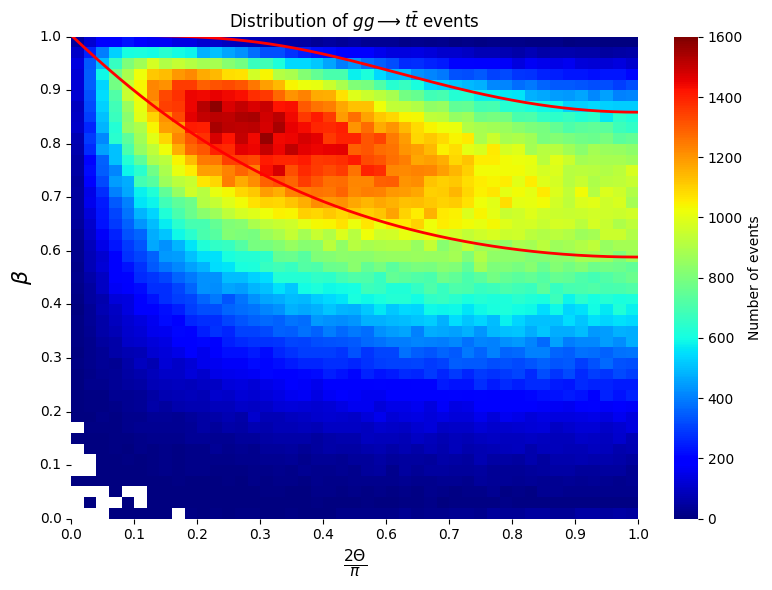

In [60]:
#10.2 Distribution in terms of beta

def process_cell(cell):
    if isinstance(cell, list) and len(cell) > 0:
        return distrib_num(cell)
    else:
        return np.nan

processed_map = binned_matrix2.map(process_cell)

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    processed_map, 
    cmap='jet',      
    vmin=0.0,         
    vmax=1600.0, 
    cbar_kws={'label': 'Number of events'},
    ax=ax
)

bin_n_y, bin_n_x = processed_map.shape
theta_min = processed_map.columns[0].left
theta_max = processed_map.columns[-1].right
beta_min = processed_map.index[0].left
beta_max = processed_map.index[-1].right
theta_fine = np.linspace(0, 1, 500)
theta_rad = theta_fine * (np.pi / 2.0)
sin_t = np.sin(theta_rad)
sin2_t = sin_t**2
sin4_t = sin_t**4
beta_low = np.sqrt((1.0 + sin2_t - np.sqrt(2.0) * sin_t) / (1.0 + sin4_t))
beta_up = 1.0 / (1.0 + sin4_t) ** 0.25
X_pixels = theta_fine / theta_max * bin_n_x
Y1_pixels = beta_low / beta_max * bin_n_y
Y2_pixels = beta_up / beta_max * bin_n_y
ax.plot(X_pixels, Y1_pixels, color='red', linewidth=2.0)
ax.plot(X_pixels, Y2_pixels, color='red', linewidth=2.0)

ax.invert_yaxis()
num_ticks = 10
x_positions = np.linspace(0, bin_n_x, num_ticks)
y_positions = np.linspace(0, bin_n_y, num_ticks)
x_values = np.linspace(0, 1, num_ticks)
y_values = np.linspace(0, 1, num_ticks)
x_labels = [f"{val:.1f}" for val in x_values]
y_labels = [f"{val:.1f}" for val in y_values]

ax.set_xticks(x_positions)
ax.set_xticklabels(x_labels, rotation=0) 
ax.set_yticks(y_positions)
ax.set_yticklabels(y_labels, rotation=0)

ax.set_title(r"Distribution of $gg \longrightarrow t\bar{t}$ events")
ax.set_xlabel(r"$\frac{2\Theta}{\pi}$", fontsize=16)
ax.set_ylabel(r"$\beta$", fontsize=16)

plt.tight_layout()
plt.show()